# Atlanta Braves Holdings | Financial Performance & Revenue Strategy

**CFO Decision Support Analysis — FY2023–FY2025 and H1 2026**

## Objective

Evaluate the financial performance of Atlanta Braves Holdings and identify the commercial and operational priorities that warrant management attention.

The analysis examines revenue composition, operating profitability, attendance trends, business segment performance, and the financial implications of the transition to BravesVision.

## Analytical Questions

1. Which revenue streams are driving growth?
2. Why can operating performance deteriorate despite revenue growth?
3. How are Baseball and Mixed-Use Development contributing to results?
4. Which risks and investments should management evaluate for future budgeting decisions?

## Data

Primary sources: Atlanta Braves Holdings' SEC Form 10-K for FY2025 and Form 10-Q for the six months ended June 30, 2026.

Historical figures are reported actuals. Financial scenarios introduced later will be explicitly labeled as assumptions.

All figures are in USD unless otherwise stated.

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Atlanta Braves Holdings
# Audited FY2025 10-K, covering 2023–2025
# All financial amounts in USD thousands

SOURCE_10K = (
    "https://www.sec.gov/Archives/edgar/data/"
    "1958140/000110465926020650/"
    "batra-20251231x10k.htm"
)

annual = pd.DataFrame({
    "year": [2023, 2024, 2025],

    "baseball_event": [339485, 347925, 357849],
    "broadcasting": [160944, 166094, 188586],
    "retail_licensing": [51533, 47754, 46489],
    "other_baseball": [29709, 33657, 42136],
    "mixed_use": [58996, 67318, 97432],

    "baseball_costs": [482391, 504146, 496987],
    "mixed_use_costs": [8834, 9762, 14363],
    "sga": [124902, 125676, 128904],
    "impairment": [0, 0, 30131],
    "depreciation_amortization": [70980, 62829, 75634],

    "reported_operating_income": [-46440, -39665, -13527]
})

# Reconstruct reported revenue
annual["baseball_revenue"] = annual[
    ["baseball_event", "broadcasting",
     "retail_licensing", "other_baseball"]
].sum(axis=1)

annual["total_revenue"] = (
    annual["baseball_revenue"] + annual["mixed_use"]
)

# Reconstruct GAAP operating expenses
annual["operating_expenses"] = annual[
    ["baseball_costs", "mixed_use_costs",
     "sga", "impairment",
     "depreciation_amortization"]
].sum(axis=1)

annual["operating_income"] = (
    annual["total_revenue"] - annual["operating_expenses"]
)

# Financial reconciliation control
assert (
    annual["operating_income"]
    == annual["reported_operating_income"]
).all(), "Operating income reconciliation failed"

# CFO summary
summary = pd.DataFrame({
    "Year": annual["year"],
    "Revenue ($M)": annual["total_revenue"] / 1000,
    "Operating expenses ($M)": annual["operating_expenses"] / 1000,
    "Operating income ($M)": annual["operating_income"] / 1000,
    "Operating margin (%)": (
        annual["operating_income"] /
        annual["total_revenue"] * 100
    )
}).round(2)

print("PASS: Financial statements reconciled.")
display(summary)


PASS: Financial statements reconciled.


,Year,Revenue ($M),Operating expenses ($M),Operating income ($M),Operating margin (%)
0,2023,640.67,687.11,-46.44,-7.25
1,2024,662.75,702.41,-39.66,-5.98
2,2025,732.49,746.02,-13.53,-1.85


## 2. Year-over-Year Financial Performance — 2024 vs. 2025

PASS: Operating profit bridge reconciled.
Change in operating income: $26.14M


,Driver,Type,Operating profit impact ($M)
0,Baseball events,Revenue,9.92
1,Broadcasting,Revenue,22.49
2,Retail and licensing,Revenue,-1.26
3,Other baseball,Revenue,8.48
4,Mixed-use development,Revenue,30.11
5,Baseball operating costs,Expense,7.16
6,Mixed-use costs,Expense,-4.60
7,SG&A,Expense,-3.23
8,Impairment,Expense,-30.13
9,Depreciation & amortization,Expense,-12.80


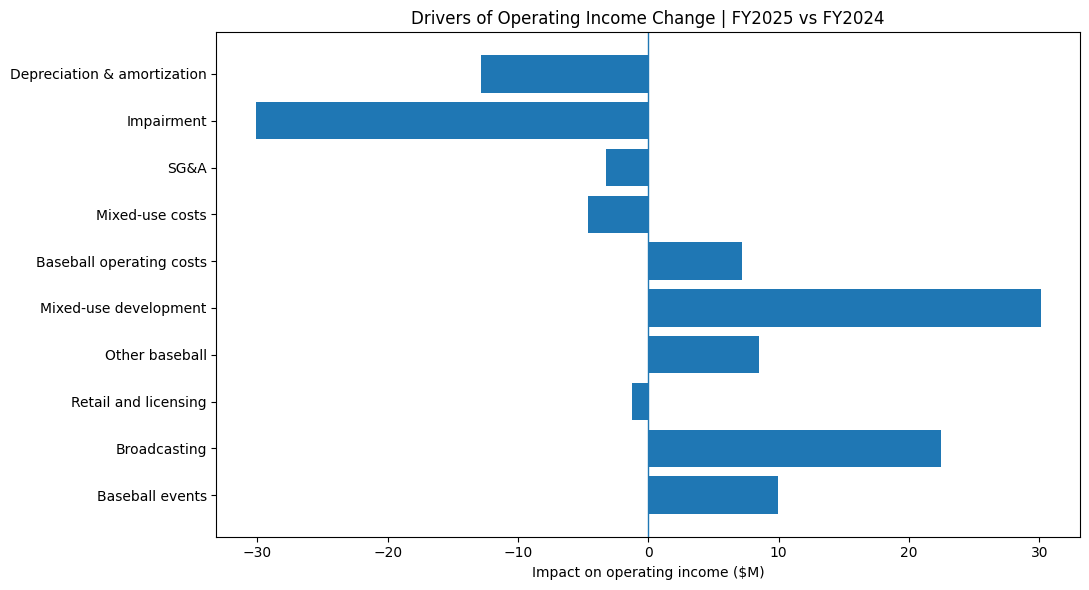

In [14]:

# FY2024 to FY2025 financial performance bridge
# USD thousands in source data

revenue_items = {
    "Baseball events": "baseball_event",
    "Broadcasting": "broadcasting",
    "Retail and licensing": "retail_licensing",
    "Other baseball": "other_baseball",
    "Mixed-use development": "mixed_use"
}

expense_items = {
    "Baseball operating costs": "baseball_costs",
    "Mixed-use costs": "mixed_use_costs",
    "SG&A": "sga",
    "Impairment": "impairment",
    "Depreciation & amortization":
        "depreciation_amortization"
}

fy24 = annual.set_index("year").loc[2024]
fy25 = annual.set_index("year").loc[2025]

drivers = []

for label, column in revenue_items.items():
    change = fy25[column] - fy24[column]
    drivers.append({
        "Driver": label,
        "Type": "Revenue",
        "Operating profit impact ($M)": change / 1000
    })

for label, column in expense_items.items():
    change = fy25[column] - fy24[column]
    drivers.append({
        "Driver": label,
        "Type": "Expense",
        "Operating profit impact ($M)": -change / 1000
    })

bridge = pd.DataFrame(drivers)

# Check the bridge against reported results
reported_improvement = (
    fy25["operating_income"] -
    fy24["operating_income"]
) / 1000

assert np.isclose(
    bridge["Operating profit impact ($M)"].sum(),
    reported_improvement
)

print("PASS: Operating profit bridge reconciled.")
print(
    f"Change in operating income: "
    f"${reported_improvement:,.2f}M"
)

display(bridge.round(2))

# Visualize positive and negative contributions
fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    bridge["Driver"],
    bridge["Operating profit impact ($M)"]
)

ax.axvline(0, linewidth=1)
ax.set_xlabel("Impact on operating income ($M)")
ax.set_title(
    "Drivers of Operating Income Change | FY2025 vs FY2024"
)

plt.tight_layout()
plt.show()


## 3. Segment Performance and Adjusted Operating Margins

PASS: Segment Adjusted OIBDA reconciled.


,year,segment,revenue_m,adjusted_oibda_m,adjusted_margin_pct
0,2024,Baseball,595.43,6.62,1.11
1,2024,Mixed-Use Development,67.32,45.45,67.51
2,2025,Baseball,635.06,51.10,8.05
3,2025,Mixed-Use Development,97.43,68.53,70.33


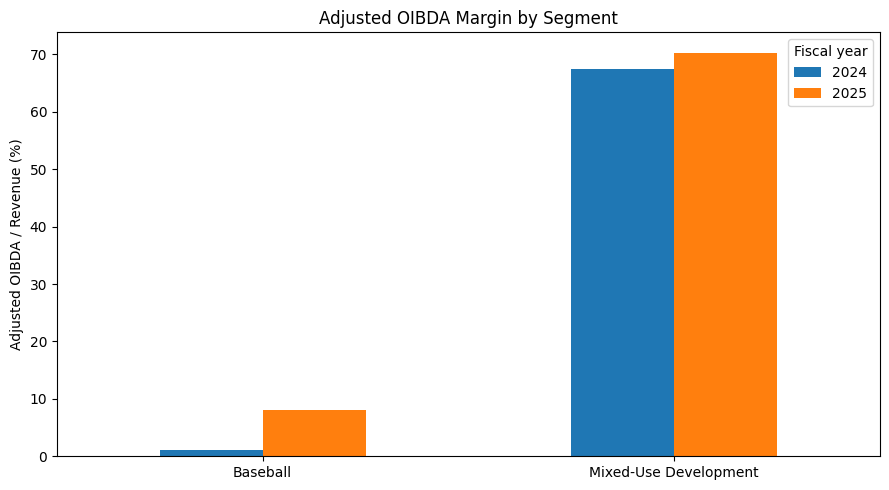

In [15]:

# Reported segment Adjusted OIBDA
# Source: FY2025 Form 10-K
# All values in USD thousands

segments = pd.DataFrame({
    "year": [2024, 2024, 2025, 2025],
    "segment": [
        "Baseball", "Mixed-Use Development",
        "Baseball", "Mixed-Use Development"
    ],
    "revenue": [
        595430, 67318,
        635060, 97432
    ],
    "adjusted_oibda": [
        6625, 45448,
        51104, 68527
    ]
})

segments["adjusted_margin_pct"] = (
    segments["adjusted_oibda"] /
    segments["revenue"] * 100
)

segments["revenue_m"] = (
    segments["revenue"] / 1000
)

segments["adjusted_oibda_m"] = (
    segments["adjusted_oibda"] / 1000
)

# Reconcile segment figures to consolidated
corporate_oibda = {
    2024: -12390,
    2025: -11818
}

reported_consolidated = {
    2024: 39683,
    2025: 107813
}

for year in [2024, 2025]:
    segment_total = segments.loc[
        segments["year"] == year,
        "adjusted_oibda"
    ].sum()

    assert (
        segment_total + corporate_oibda[year]
        == reported_consolidated[year]
    )

print("PASS: Segment Adjusted OIBDA reconciled.")

display(
    segments[
        ["year", "segment", "revenue_m",
         "adjusted_oibda_m", "adjusted_margin_pct"]
    ].round(2)
)

# Compare segment margins
margin_chart = segments.pivot(
    index="segment",
    columns="year",
    values="adjusted_margin_pct"
)

ax = margin_chart.plot.bar(
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "Adjusted OIBDA Margin by Segment"
)
ax.set_ylabel("Adjusted OIBDA / Revenue (%)")
ax.set_xlabel("")
ax.legend(title="Fiscal year")

plt.tight_layout()
plt.show()


## 4. H1 2026 — Revenue Growth vs. Operating Performance

PASS: H1 financial figures reconciled.

Financial performance ($M)


,year,reported_revenue,reported_oibda,gaap_operating_income
0,2025,359.65,37.16,-2.66
1,2026,377.13,-5.77,-59.79



Adjusted OIBDA change by segment ($M)


,Segment,H1 2025,H1 2026,Change ($M)
0,Baseball,12.447,-38.063,-50.510
1,Mixed-Use Development,30.453,38.237,7.784
2,Corporate and other,-5.745,-5.942,-0.197


Consolidated change: $-42.92M


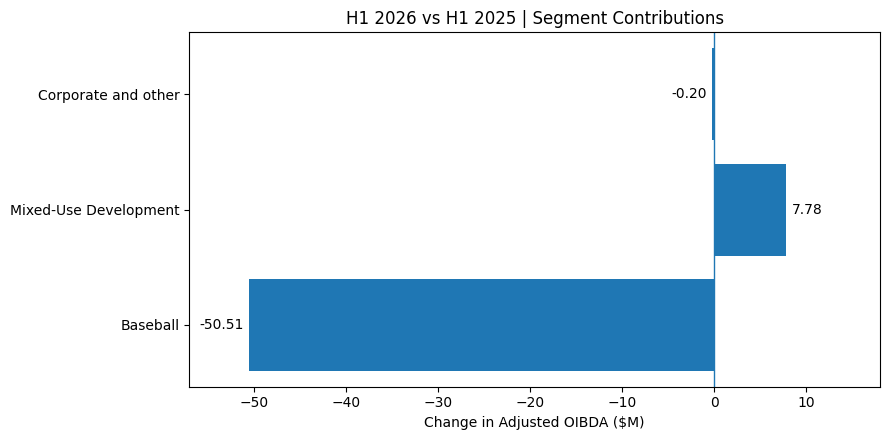

In [16]:

# H1 2026 vs H1 2025
# Source: Q2 2026 Form 10-Q
# Reported figures in USD thousands

h1 = pd.DataFrame({
    "year": [2025, 2026],
    "baseball_revenue": [315940, 322183],
    "mixed_use_revenue": [43711, 54943],
    "baseball_oibda": [12447, -38063],
    "mixed_use_oibda": [30453, 38237],
    "corporate_oibda": [-5745, -5942],
    "reported_revenue": [359651, 377126],
    "reported_oibda": [37155, -5768],
    "gaap_operating_income": [-2665, -59794],
    "home_games": [40, 39]
})

# Validate against official totals
assert (
    h1["baseball_revenue"] +
    h1["mixed_use_revenue"] ==
    h1["reported_revenue"]
).all()

assert (
    h1["baseball_oibda"] +
    h1["mixed_use_oibda"] +
    h1["corporate_oibda"] ==
    h1["reported_oibda"]
).all()

print("PASS: H1 financial figures reconciled.")

summary_h1 = h1[
    ["year", "reported_revenue",
     "reported_oibda", "gaap_operating_income"]
].copy()

for col in summary_h1.columns[1:]:
    summary_h1[col] = (
        summary_h1[col] / 1000
    ).round(2)

print("\nFinancial performance ($M)")
display(summary_h1)

# Explain the movement by business segment
drivers_h1 = pd.DataFrame({
    "Segment": [
        "Baseball",
        "Mixed-Use Development",
        "Corporate and other"
    ],
    "H1 2025": [12.447, 30.453, -5.745],
    "H1 2026": [-38.063, 38.237, -5.942]
})

drivers_h1["Change ($M)"] = (
    drivers_h1["H1 2026"] -
    drivers_h1["H1 2025"]
).round(3)

total_change = (
    h1.loc[1, "reported_oibda"] -
    h1.loc[0, "reported_oibda"]
) / 1000

assert np.isclose(
    drivers_h1["Change ($M)"].sum(),
    total_change
)

print("\nAdjusted OIBDA change by segment ($M)")
display(drivers_h1)

print(
    f"Consolidated change: ${total_change:,.2f}M"
)

# Segment contribution chart
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    drivers_h1["Segment"],
    drivers_h1["Change ($M)"]
)

ax.axvline(0, linewidth=1)
ax.bar_label(bars, fmt="%.2f", padding=4)

ax.set_xlim(-57, 18)
ax.set_xlabel("Change in Adjusted OIBDA ($M)")
ax.set_title(
    "H1 2026 vs H1 2025 | Segment Contributions"
)

plt.tight_layout()
plt.show()


## 5. H1 2026 Financial Drivers — Revenue and Cost Bridge

PASS: Detailed financial bridge reconciled.
Adjusted OIBDA change: $-42.92M


,Category,Type,Change ($M),OIBDA Impact ($M)
0,Baseball events,Revenue,3.52,3.52
1,Media related,Revenue,-9.99,-9.99
2,Retail and licensing,Revenue,4.47,4.47
3,Other baseball,Revenue,8.24,8.24
4,Mixed-use revenue,Revenue,11.23,11.23
5,Baseball operating costs,Expense,49.09,-49.09
6,Mixed-use operating costs,Expense,2.77,-2.77
7,SG&A excluding stock compensation,Expense,8.54,-8.54


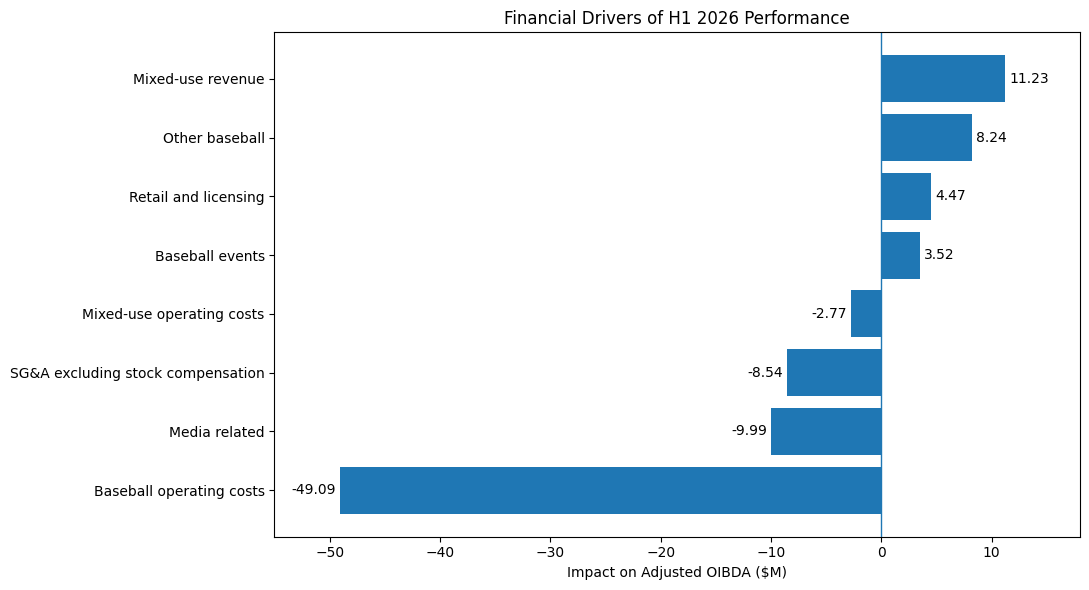

In [17]:

# Detailed H1 2026 vs H1 2025 financial bridge
# Source: Atlanta Braves Holdings Q2 2026 Form 10-Q
# All source amounts are USD thousands

financial_drivers = pd.DataFrame({
    "Category": [
        "Baseball events",
        "Media related",
        "Retail and licensing",
        "Other baseball",
        "Mixed-use revenue",
        "Baseball operating costs",
        "Mixed-use operating costs",
        "SG&A excluding stock compensation"
    ],
    "Type": [
        "Revenue", "Revenue", "Revenue", "Revenue",
        "Revenue", "Expense", "Expense", "Expense"
    ],
    "H1 2025": [
        181232, 85359, 24646, 24703,
        43711, 259572, 6041, 56883
    ],
    "H1 2026": [
        184749, 75372, 29119, 32943,
        54943, 308658, 8811, 65425
    ]
})

# Revenue increases help performance.
# Expense increases reduce performance.

financial_drivers["Change ($M)"] = (
    financial_drivers["H1 2026"] -
    financial_drivers["H1 2025"]
) / 1000

financial_drivers["OIBDA Impact ($M)"] = np.where(
    financial_drivers["Type"] == "Revenue",
    financial_drivers["Change ($M)"],
    -financial_drivers["Change ($M)"]
)

# Reconcile revenues and Adjusted OIBDA
for year in [2025, 2026]:
    col = f"H1 {year}"

    revenue = financial_drivers.loc[
        financial_drivers["Type"] == "Revenue", col
    ].sum()

    costs = financial_drivers.loc[
        financial_drivers["Type"] == "Expense", col
    ].sum()

    expected = h1.set_index("year").loc[year]

    assert revenue == expected["reported_revenue"]
    assert (
        revenue - costs
        == expected["reported_oibda"]
    )

oibda_change = financial_drivers[
    "OIBDA Impact ($M)"
].sum()

reported_change = (
    h1.set_index("year").loc[2026, "reported_oibda"] -
    h1.set_index("year").loc[2025, "reported_oibda"]
) / 1000

assert np.isclose(
    oibda_change, reported_change
)

print("PASS: Detailed financial bridge reconciled.")
print(
    f"Adjusted OIBDA change: "
    f"${oibda_change:,.2f}M"
)

display(
    financial_drivers[
        ["Category", "Type", "Change ($M)",
         "OIBDA Impact ($M)"]
    ].round(2)
)

# Visualize contributions
chart_data = financial_drivers.sort_values(
    "OIBDA Impact ($M)"
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    chart_data["Category"],
    chart_data["OIBDA Impact ($M)"]
)

ax.axvline(0, linewidth=1)

ax.bar_label(
    bars, fmt="%.2f", padding=3
)

ax.set_xlim(-55, 18)
ax.set_xlabel(
    "Impact on Adjusted OIBDA ($M)"
)
ax.set_title(
    "Financial Drivers of H1 2026 Performance"
)

plt.tight_layout()
plt.show()


## 6. CFO Decision Model — Operating Improvement Scenarios

Actual H1 2026 OIBDA: $-5.77M
Improvement needed to break even: $5.77M


,Scenario,Media contribution,Commercial contribution,Net operating cost savings,Total improvement,Pro forma H1 OIBDA
0,Conservative,0.8,0.4,0,1.2,-4.57
1,Base,3.3,1.5,2,6.8,1.03
2,Upside,6.5,3.0,4,13.5,7.73


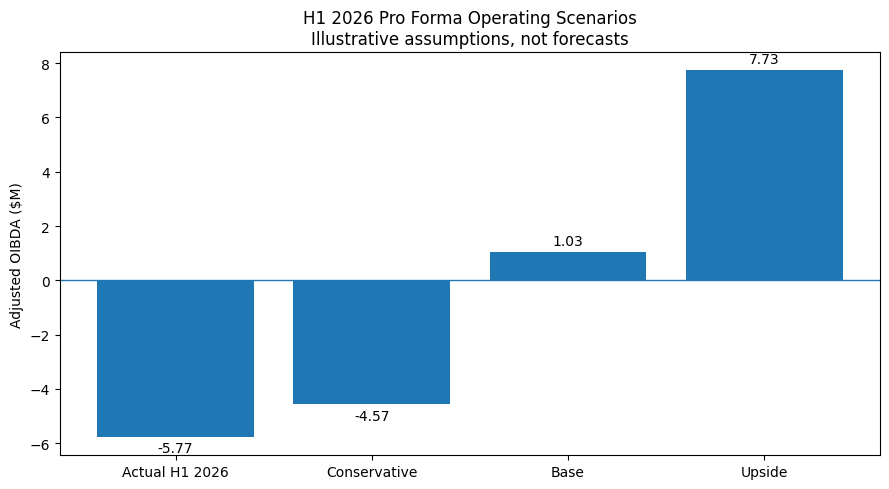

In [18]:

# CFO scenario analysis
# USD millions
# All scenarios are hypothetical, not company guidance.

baseline_oibda = (
    h1.set_index("year")
    .loc[2026, "reported_oibda"] / 1000
)

scenarios = pd.DataFrame({
    "Scenario": [
        "Conservative", "Base", "Upside"
    ],
    "Additional media revenue": [2, 6, 10],
    "Media contribution margin": [0.40, 0.55, 0.65],
    "Net operating cost savings": [0, 2, 4],
    "Additional commercial revenue": [1, 3, 5],
    "Commercial contribution margin": [0.40, 0.50, 0.60]
})

# Revenue is not pure profit.
# Apply contribution margins to incremental revenue.

scenarios["Media contribution"] = (
    scenarios["Additional media revenue"] *
    scenarios["Media contribution margin"]
)

scenarios["Commercial contribution"] = (
    scenarios["Additional commercial revenue"] *
    scenarios["Commercial contribution margin"]
)

scenarios["Total improvement"] = (
    scenarios["Media contribution"] +
    scenarios["Commercial contribution"] +
    scenarios["Net operating cost savings"]
)

scenarios["Pro forma H1 OIBDA"] = (
    baseline_oibda +
    scenarios["Total improvement"]
)

# Determine the breakeven requirement
breakeven_gap = max(0, -baseline_oibda)

print(f"Actual H1 2026 OIBDA: ${baseline_oibda:.2f}M")
print(f"Improvement needed to break even: ${breakeven_gap:.2f}M")

display(
    scenarios[
        ["Scenario",
         "Media contribution",
         "Commercial contribution",
         "Net operating cost savings",
         "Total improvement",
         "Pro forma H1 OIBDA"]
    ].round(2)
)

# Compare hypothetical outcomes with actual baseline

fig, ax = plt.subplots(figsize=(9, 5))

labels = ["Actual H1 2026"] + scenarios["Scenario"].tolist()
values = [baseline_oibda] + scenarios["Pro forma H1 OIBDA"].tolist()

bars = ax.bar(labels, values)

ax.axhline(0, linewidth=1)
ax.bar_label(bars, fmt="%.2f", padding=3)

ax.set_ylabel("Adjusted OIBDA ($M)")
ax.set_title(
    "H1 2026 Pro Forma Operating Scenarios\n"
    "Illustrative assumptions, not forecasts"
)

plt.tight_layout()
plt.show()


## 7. Financial Risk Analysis — Breakeven and Sensitivity Testing

In [19]:

# CFO sensitivity analysis
# All amounts in USD millions
# Illustrative scenarios, not financial forecasts

baseline = (
    h1.set_index("year")
    .loc[2026, "reported_oibda"] / 1000
)

breakeven_gap = max(0, -baseline)

# Hold commercial assumptions constant
commercial_revenue = 3.0
commercial_margin = 0.50

commercial_contribution = (
    commercial_revenue * commercial_margin
)

# Test different media margins and savings targets
media_margins = [0.40, 0.55, 0.65]
savings_targets = [0, 2, 4]

results = []

for savings in savings_targets:
    for margin in media_margins:

        remaining_gap = max(
            0,
            breakeven_gap -
            commercial_contribution -
            savings
        )

        required_media_revenue = (
            remaining_gap / margin
        )

        results.append({
            "Cost savings ($M)": savings,
            "Media margin": f"{margin:.0%}",
            "Required media revenue ($M)":
                required_media_revenue
        })

sensitivity_table = pd.DataFrame(results)

print("MEDIA REVENUE REQUIRED TO BREAK EVEN")

display(
    sensitivity_table.pivot(
        index="Cost savings ($M)",
        columns="Media margin",
        values="Required media revenue ($M)"
    ).round(2)
)

# Stress-test the original Base scenario
stress_tests = pd.DataFrame({
    "Case": [
        "Original Base",
        "Media revenue -20%",
        "Media margin reduced to 40%",
        "Both adverse changes"
    ],
    "Media revenue": [6.0, 4.8, 6.0, 4.8],
    "Media margin": [0.55, 0.55, 0.40, 0.40]
})

stress_tests["Pro forma OIBDA ($M)"] = (
    baseline +
    stress_tests["Media revenue"] *
    stress_tests["Media margin"] +
    commercial_contribution +
    2.0
).round(2)

stress_tests["Break even?"] = np.where(
    stress_tests["Pro forma OIBDA ($M)"] >= 0,
    "Yes",
    "No"
)

print("\nBASE SCENARIO STRESS TEST")
display(stress_tests)


MEDIA REVENUE REQUIRED TO BREAK EVEN


Media margin,40%,55%,65%
Cost savings ($M),,,
0,10.67,7.76,6.57
2,5.67,4.12,3.49
4,0.67,0.49,0.41



BASE SCENARIO STRESS TEST


,Case,Media revenue,Media margin,Pro forma OIBDA ($M),Break even?
0,Original Base,6.0,0.55,1.03,Yes
1,Media revenue -20%,4.8,0.55,0.37,Yes
2,Media margin reduced to 40%,6.0,0.40,0.13,Yes
3,Both adverse changes,4.8,0.40,-0.35,No


## 8. Cash Flow, Capital Investment and Liquidity

PASS: Cash-flow statements reconciled.


,year,operating_cf,capex,cash_after_capex,investing_cf,financing_cf,ending_cash_incl_restricted
0,2025,87.64,36.40,51.24,-130.10,83.49,153.62
1,2026,-1.65,15.88,-17.52,-15.87,84.90,178.96


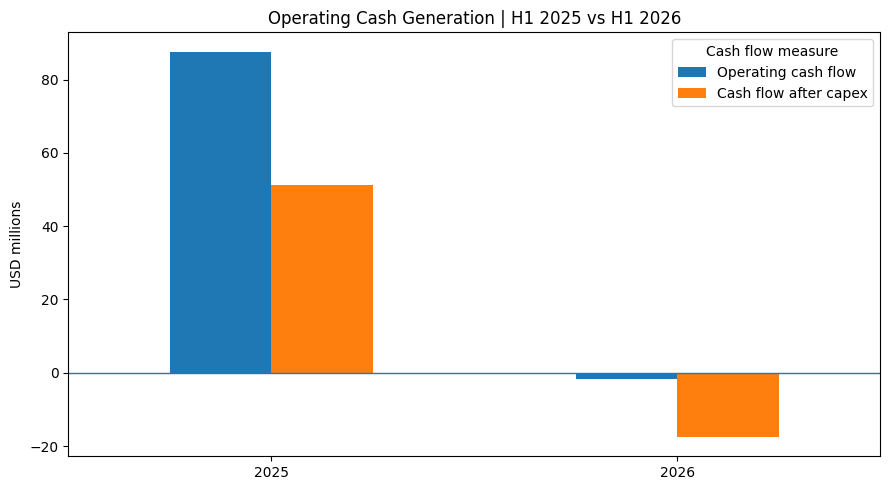


Cash and equivalents: $116.28M
Restricted cash: $62.68M


In [20]:

# Atlanta Braves Holdings
# H1 2025 and H1 2026 cash-flow statements
# Source: June 30, 2026 Form 10-Q
# All source values in USD thousands

cashflows = pd.DataFrame({
    "year": [2025, 2026],
    "operating_cf": [87640, -1647],
    "capex": [36400, 15875],
    "real_estate_acquisitions": [93709, 0],
    "investing_cf": [-130105, -15871],
    "financing_cf": [83487, 84899],
    "reported_cash_change": [41022, 67381],
    "beginning_cash_incl_restricted": [112599, 111578],
    "ending_cash_incl_restricted": [153621, 178959]
})

# Simplified free cash flow proxy:
# operating cash flow minus property/equipment capex
# This excludes real-estate acquisitions.

cashflows["cash_after_capex"] = (
    cashflows["operating_cf"] - cashflows["capex"]
)

# Validate reported cash movement
cashflows["calculated_cash_change"] = (
    cashflows["operating_cf"] +
    cashflows["investing_cf"] +
    cashflows["financing_cf"]
)

assert (
    cashflows["calculated_cash_change"] ==
    cashflows["reported_cash_change"]
).all()

assert (
    cashflows["beginning_cash_incl_restricted"] +
    cashflows["reported_cash_change"] ==
    cashflows["ending_cash_incl_restricted"]
).all()

print("PASS: Cash-flow statements reconciled.")

# CFO summary in millions
columns = [
    "operating_cf",
    "capex",
    "cash_after_capex",
    "investing_cf",
    "financing_cf",
    "ending_cash_incl_restricted"
]

cash_summary = cashflows[
    ["year"] + columns
].copy()

cash_summary[columns] = (
    cash_summary[columns] / 1000
).round(2)

display(cash_summary)

# Visual comparison
chart_data = cashflows.set_index("year")[
    ["operating_cf", "cash_after_capex"]
] / 1000

chart_data.columns = [
    "Operating cash flow",
    "Cash flow after capex"
]

ax = chart_data.plot.bar(
    figsize=(9, 5),
    rot=0
)

ax.axhline(0, linewidth=1)
ax.set_ylabel("USD millions")
ax.set_xlabel("")
ax.set_title(
    "Operating Cash Generation | H1 2025 vs H1 2026"
)

ax.legend(title="Cash flow measure")

plt.tight_layout()
plt.show()

# June 30, 2026 balance-sheet liquidity snapshot
cash_available = 116278
restricted_cash = 62681

assert (
    cash_available + restricted_cash ==
    cashflows.loc[
        cashflows["year"] == 2026,
        "ending_cash_incl_restricted"
    ].iloc[0]
)

print(
    f"\nCash and equivalents: "
    f"${cash_available / 1000:.2f}M"
)

print(
    f"Restricted cash: "
    f"${restricted_cash / 1000:.2f}M"
)


## 9. Balance Sheet, Debt and Liquidity Analysis

PASS: Balance sheet totals reconciled.


,period,cash,restricted_cash,total_debt,net_debt,current_ratio,working_capital
0,FY2025 End,99.88,11.69,738.63,638.75,0.42,-218.34
1,H1 2026 End,116.28,62.68,793.13,676.85,0.49,-298.03


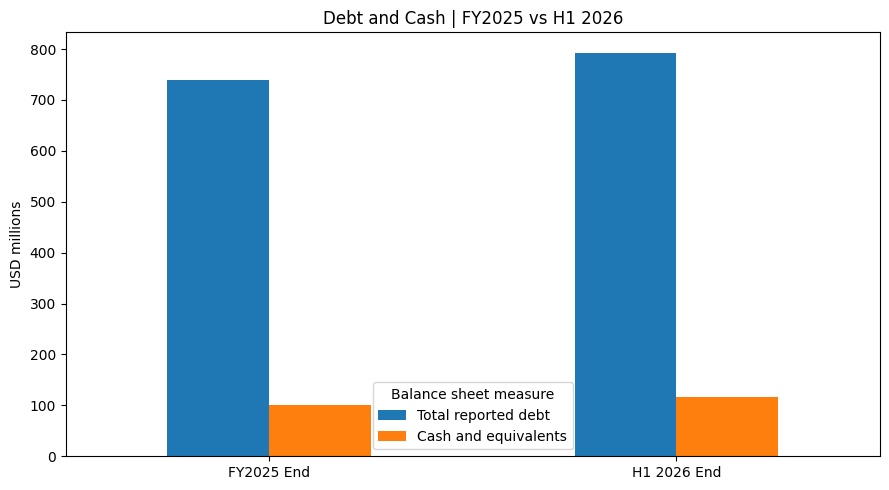

,period,current_ratio,current_ratio_ex_restricted
0,FY2025 End,0.42,0.39
1,H1 2026 End,0.49,0.38


In [21]:

# Balance sheet analysis
# Source: Q2 2026 Form 10-Q
# USD thousands

balance = pd.DataFrame({
    "period": ["FY2025 End", "H1 2026 End"],
    "cash": [99884, 116278],
    "restricted_cash": [11694, 62681],
    "current_assets": [158707, 287878],
    "current_liabilities": [377043, 585908],
    "current_debt": [215347, 333236],
    "long_term_debt": [523284, 459891]
})

balance["total_debt"] = (
    balance["current_debt"] +
    balance["long_term_debt"]
)

balance["current_ratio"] = (
    balance["current_assets"] /
    balance["current_liabilities"]
)

balance["working_capital"] = (
    balance["current_assets"] -
    balance["current_liabilities"]
)

balance["net_debt"] = (
    balance["total_debt"] - balance["cash"]
)

assert balance.loc[1, "total_debt"] == 793127

print("PASS: Balance sheet totals reconciled.")

summary = balance[
    ["period", "cash", "restricted_cash",
     "total_debt", "net_debt",
     "current_ratio", "working_capital"]
].copy()

money_columns = [
    "cash", "restricted_cash",
    "total_debt", "net_debt",
    "working_capital"
]

summary[money_columns] = (
    summary[money_columns] / 1000
).round(2)

display(summary.round(2))

# Compare debt against cash

chart = balance.set_index("period")[
    ["total_debt", "cash"]
] / 1000

chart.columns = [
    "Total reported debt",
    "Cash and equivalents"
]

ax = chart.plot.bar(figsize=(9, 5), rot=0)

ax.set_title("Debt and Cash | FY2025 vs H1 2026")
ax.set_ylabel("USD millions")
ax.set_xlabel("")
ax.legend(title="Balance sheet measure")

plt.tight_layout()
plt.show()


# Supplemental liquidity ratio excluding restricted cash

balance["current_ratio_ex_restricted"] = (
    (balance["current_assets"] - balance["restricted_cash"])
    / balance["current_liabilities"]
)

display(
    balance[
        ["period", "current_ratio",
         "current_ratio_ex_restricted"]
    ].round(2)
)



## 10. Executive Decision Memo — Financial Priorities

# Atlanta Braves Holdings — Financial Review and Management Priorities

**To:** Chief Financial Officer  
**From:** Business Analytics  
**Reporting period:** FY2023–FY2025 and H1 2026  
**Basis:** Public SEC filings; independent analysis

## Executive Summary

Atlanta Braves Holdings entered 2026 after revenue increased in both 2024 and 2025, alongside improving annual GAAP operating results. However, its first-half 2026 performance revealed a deterioration in operating profitability and cash generation.

H1 revenue increased by $17.48 million year over year, while Adjusted OIBDA declined by $42.92 million to negative $5.77 million. The Baseball segment accounted for a $50.51 million decline, partially offset by a $7.78 million improvement in Mixed-Use Development.

Operating cash flow fell from positive $87.64 million to negative $1.65 million. Cash flow after capital expenditures declined to negative $17.52 million.

The main financial priority should be improving visibility into future cash generation and evaluating the economics of the broadcasting transition while maintaining adequate liquidity for existing commitments.

## Recommended Management Priorities

### 1. Protect liquidity and manage financing requirements

Total reported debt reached $793.13 million at June 30, 2026, while cash and cash equivalents totaled $116.28 million.

Although the company reported compliance with its debt covenants, the increase in current debt, negative working capital, and weaker operating cash generation warrant active monitoring.

**Recommended actions:**

- Develop a rolling 13-week cash-flow forecast and update it against actual results.
- Review upcoming debt maturities, refinancing alternatives, covenant headroom, and facility restrictions.
- Separate unrestricted cash, restricted cash, and conditional borrowing capacity in liquidity reporting.
- Review discretionary capital commitments against projected cash requirements.

**Decision required:** Determine whether planned investments can proceed without compromising liquidity under downside operating scenarios.

### 2. Validate the economics of BravesVision

Media-related revenue declined by $9.99 million year over year, while BravesVision production expenses contributed to increased operating costs.

The publicly available financial statements do not provide enough information to evaluate BravesVision as a standalone investment.

**Recommended actions:**

- Develop a dedicated broadcasting contribution model covering distribution revenue, subscriptions, advertising, production costs, and customer acquisition expenses.
- Separate transitional launch costs from recurring operating costs.
- Evaluate incremental cash contribution and investment payback under multiple adoption scenarios.

**Decision required:** Establish financial performance milestones before committing further discretionary capital to broadcasting expansion.

### 3. Improve cost visibility without weakening baseball operations

Baseball operating costs increased by $49.09 million in H1 2026 and were the largest unfavorable driver in the financial bridge.

However, player payroll and other baseball costs are tied to contracts and competitive objectives. They should not be treated as uniformly discretionary.

**Recommended actions:**

- Separate committed player compensation from controllable operating expenses.
- Identify recurring versus transitional costs.
- Introduce regular budget-to-actual variance reporting.
- Evaluate cost changes alongside their operational and competitive effects.

**Decision required:** Identify sustainable efficiency opportunities without assuming that lower baseball spending automatically produces better organizational outcomes.

### 4. Evaluate Mixed-Use Development through cash returns

Mixed-Use Development generated $68.53 million in FY2025 Adjusted OIBDA, exceeding the Baseball segment despite generating substantially less revenue.

The segment provides meaningful diversification. Nevertheless, high adjusted margins do not establish attractive returns on new investment.

**Recommended actions:**

- Evaluate property-level operating cash flow and capital requirements.
- Separate acquired-property growth from existing-property performance.
- Assess proposed projects using cash-flow forecasts, investment returns, and financing requirements.

**Decision required:** Prioritize projects that demonstrate attractive risk-adjusted returns after considering their capital intensity.

## Scenario Analysis

The illustrative Base scenario generates $6.80 million in incremental operating contribution, sufficient to move H1 2026 Adjusted OIBDA from negative $5.77 million to positive $1.03 million.

However, applying both a 20% reduction in assumed incremental media revenue and a lower media contribution margin results in negative $0.35 million.

These scenarios demonstrate the sensitivity of operating performance to commercial assumptions. They are not management forecasts and do not establish investment feasibility.

## Management Dashboard — Proposed KPIs

| Priority | KPI | Purpose |
|---|---|---|
| Liquidity | Rolling cash forecast variance | Identify funding gaps early |
| Liquidity | Unrestricted cash and debt maturity schedule | Assess financing flexibility |
| Broadcasting | Incremental contribution margin | Evaluate commercial economics |
| Broadcasting | Customer acquisition cost and retention | Assess revenue sustainability |
| Baseball operations | Actual vs. budget by controllable cost category | Identify material cost variances |
| Mixed-use development | Property-level cash return on invested capital | Evaluate investment performance |

## Final Recommendation

I recommend a liquidity-first approach to financial planning, supported by a detailed broadcasting economics review and stronger operating-cost accountability.

Further investment should be evaluated based on incremental cash returns, downside risk, and financing capacity rather than revenue growth or Adjusted OIBDA alone.

The available public information supports these management priorities but is insufficient to approve specific capital allocations.

**Next step:** Validate the analysis with internal operating budgets, cash-flow forecasts, debt schedules, and commercial performance data before presenting a proposed investment budget.

---

**Source:** Atlanta Braves Holdings, Form 10-K for FY2025 and Form 10-Q for the six months ended June 30, 2026. All financial figures are historical reported amounts unless explicitly identified as illustrative scenarios.